In [7]:
import os
from pathlib import Path

ROOT = Path("/home/bibu/Desktop/Project/Flyvis/data").expanduser()   # <- replace with the folder from step 1
assert (ROOT / "responses_norm.h5").exists(), f"responses_norm.h5 not found in {ROOT}"

os.environ["FLYVIS_ROOT_DIR"] = str(ROOT)

import h5py, numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

import flyvis
print(flyvis.__file__)
print(flyvis.results_dir)

/home/bibu/flyvis/lib/python3.12/site-packages/flyvis/__init__.py
/home/bibu/Desktop/Project/Flyvis/data/results


In [8]:
with h5py.File(ROOT / "responses_norm.h5", "r") as f:
    print("top-level keys:", list(f.keys()))
    def show(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(f"{name:50s} shape={obj.shape} dtype={obj.dtype}")
    f.visititems(show)

top-level keys: ['flow']
flow/0000/cell_types                               shape=(65,) dtype=object
flow/0000/checkpoint_hashes                        shape=(50,) dtype=object
flow/0000/checkpoints                              shape=(50,) dtype=object
flow/0000/model_names                              shape=(50,) dtype=object
flow/0000/norm                                     shape=(50, 65) dtype=float32
flow/0000/rectified_norm                           shape=(50, 65) dtype=float32


In [9]:
def find(f, key):
    hits = []
    f.visititems(lambda n, o: hits.append(n) if isinstance(o, h5py.Dataset) and n.split("/")[-1] == key else None)
    if not hits:
        raise KeyError(f"{key} not found; run the layout cell above")
    return f[hits[0]][:]

def dec(arr):
    return [x.decode() if isinstance(x, bytes) else x for x in arr]

with h5py.File(ROOT / "responses_norm.h5", "r") as f:
    cell_types  = dec(find(f, "cell_types"))
    model_names = dec(find(f, "model_names"))
    norm = find(f, "norm")
    rect = find(f, "rectified_norm")

print(norm.shape, len(cell_types), len(model_names))
df = pd.DataFrame(norm, index=model_names, columns=cell_types)
df.iloc[:5, :8]

(50, 65) 65 50


,R1,R2,R3,R4,R5,R6,R7,R8
flow/0000/000,1.161276,1.035435,0.784800,1.256998,1.563759,1.715564,0.185401,1.175738
flow/0000/001,0.301256,1.658092,0.588577,0.417163,0.456688,0.178179,0.052336,0.861007
flow/0000/002,0.522188,0.505882,1.038373,0.594520,1.063960,0.713957,0.472300,0.654337
flow/0000/003,0.348726,0.273631,0.488285,0.329299,0.293724,0.302848,0.905080,0.450052
flow/0000/004,1.202342,1.082203,1.569146,1.036334,1.076069,1.145944,0.161051,0.938043


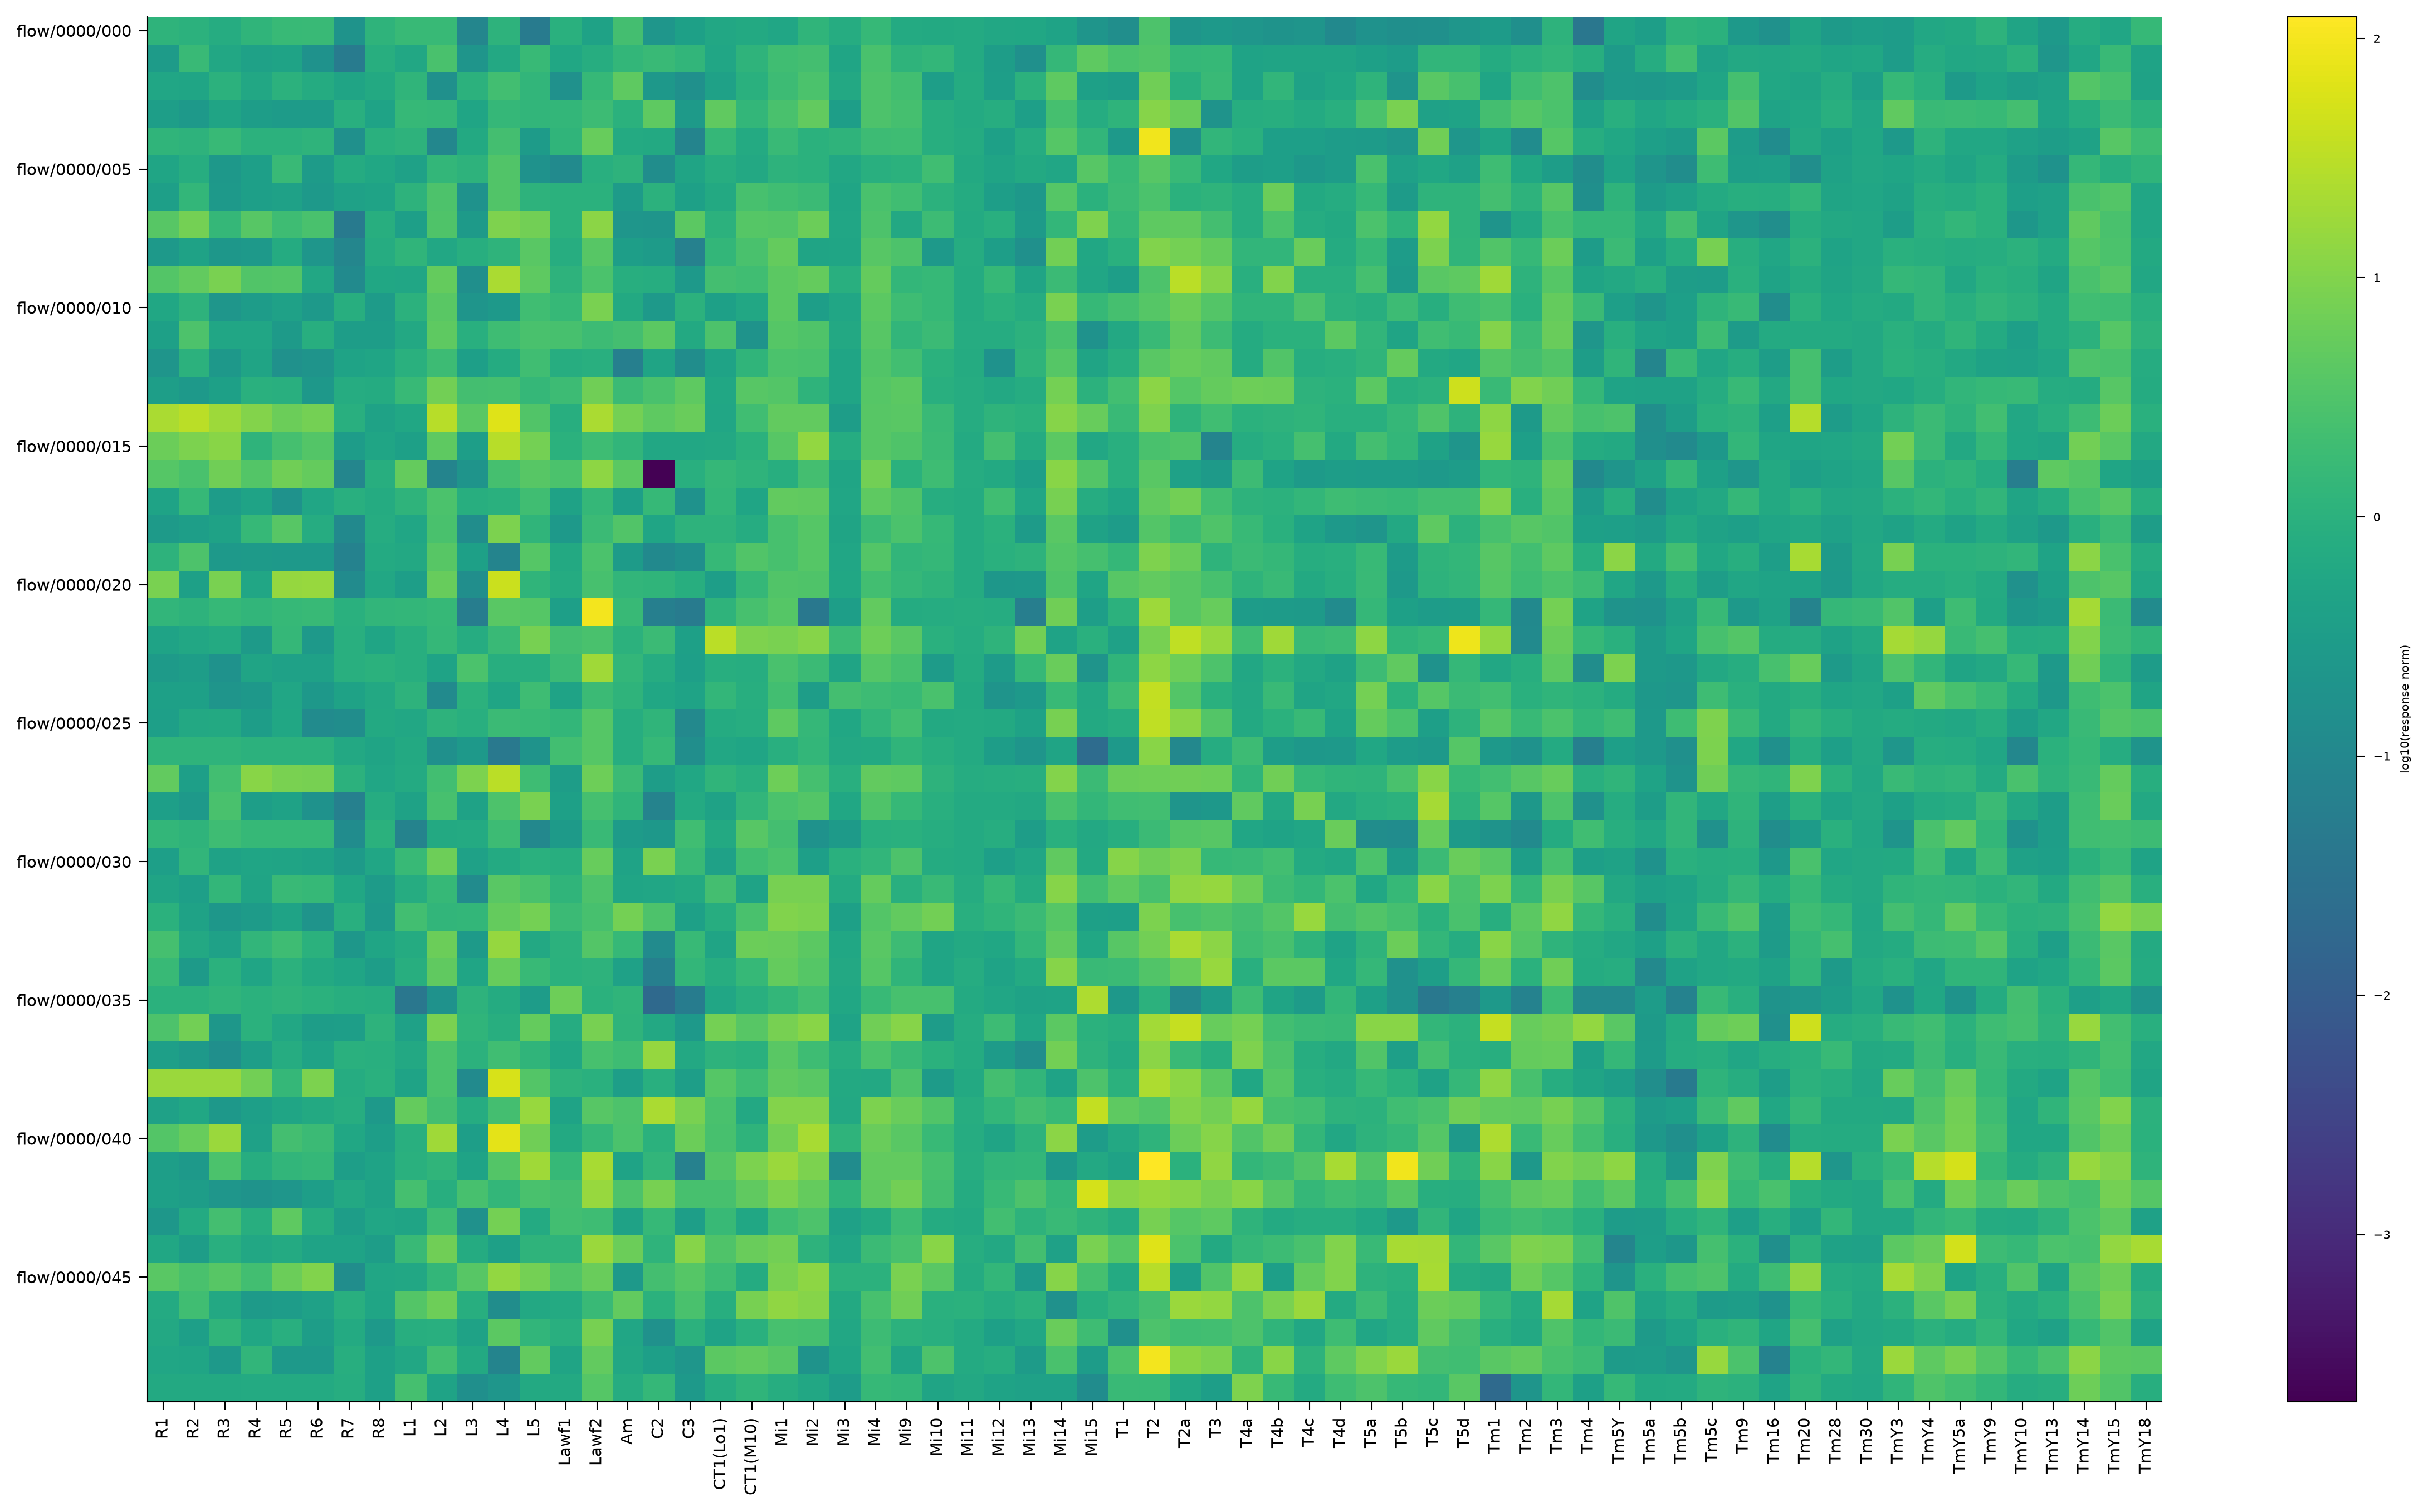

In [10]:
fig, ax = plt.subplots(figsize=(16, 9))
im = ax.imshow(np.log10(norm + 1e-4), aspect="auto", cmap="viridis")
ax.set_xticks(range(len(cell_types)))
ax.set_xticklabels(cell_types, rotation=90, fontsize=7)
ax.set_yticks(range(0, len(model_names), 5))
ax.set_yticklabels([model_names[i] for i in range(0, len(model_names), 5)], fontsize=7)
plt.colorbar(im, label="log10(response norm)")
plt.tight_layout()
plt.show()

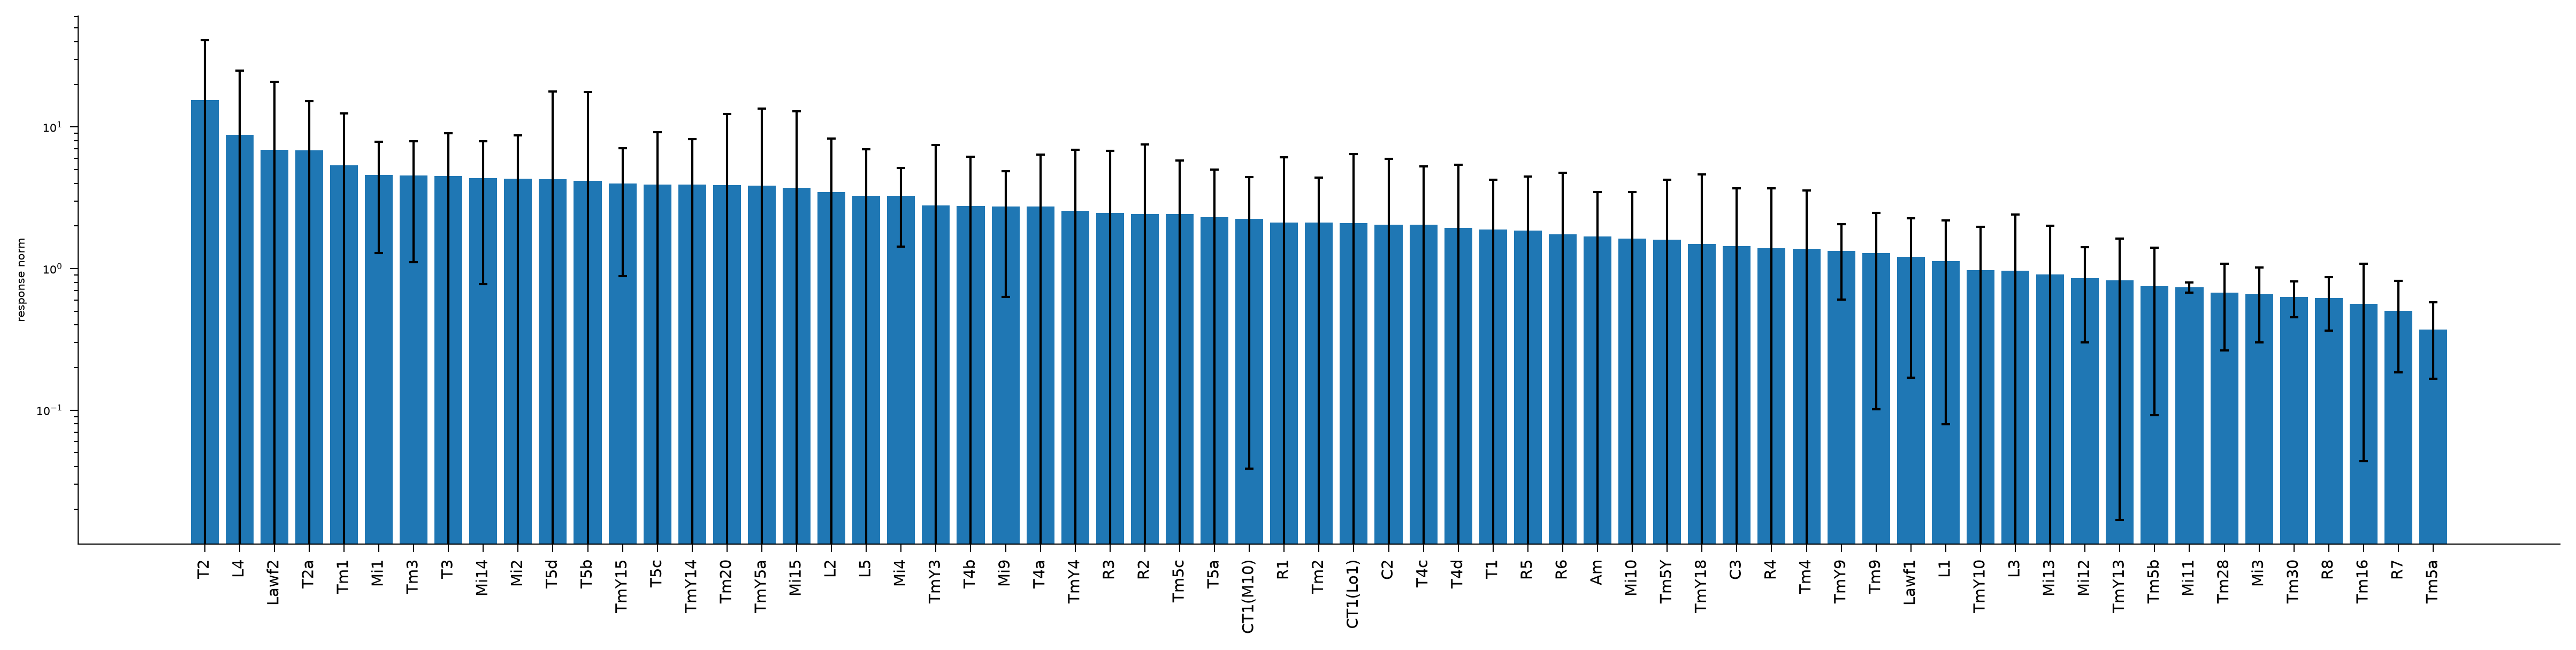

In [11]:
order = np.argsort(norm.mean(0))[::-1]
fig, ax = plt.subplots(figsize=(16, 4))
ax.bar(range(len(cell_types)), norm.mean(0)[order], yerr=norm.std(0)[order], capsize=2)
ax.set_xticks(range(len(cell_types)))
ax.set_xticklabels(np.array(cell_types)[order], rotation=90, fontsize=7)
ax.set_yscale("log")
ax.set_ylabel("response norm")
plt.tight_layout()
plt.show()